# Análisis Exploratorio - Historial de Participación

Construcción de indicadores de historial de participación (2009-2024) a nivel sección y a nivel
celda demográfica (sección x sexo x grupo de edad). Las tablas resultantes alimentan la segmentación.
Requiere haber ejecutado `01_ingesta_datos.ipynb`.

## 1. Librerías

In [1]:
import gc

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path

## 2. Rutas del proyecto

In [2]:
ROOT = Path().resolve().parent
DIR_PREPROCESSED = ROOT / "DATA" / "PREPROCESSED"

PQ_FEDERAL = DIR_PREPROCESSED / "conteos_federal_2009_2024.parquet"
PQ_PJ2025 = DIR_PREPROCESSED / "conteos_pj2025.parquet"
PQ_SECCIONES = DIR_PREPROCESSED / "secciones_historial.parquet"
PQ_CELDAS = DIR_PREPROCESSED / "celdas_historial.parquet"

print(f"Raíz del proyecto: {ROOT}")
print(f"Preprocesados:     {DIR_PREPROCESSED}")

Raíz del proyecto: C:\Users\jonat\Documentos_Locales\Repo INE HACKATHON\INE_HACKATHON
Preprocesados:     C:\Users\jonat\Documentos_Locales\Repo INE HACKATHON\INE_HACKATHON\DATA\PREPROCESSED


## 3. Configuración de visualización

Misma paleta que el perfilado. Para series categóricas (regiones) se usan los colores en órden fijo.

In [3]:
AZUL = "#2a78d6"
NARANJA = "#eb6834"
TEXTO = "#52514e"
REJILLA = "#e1e0d9"
CATEGORICOS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
CMAP_AZUL = LinearSegmentedColormap.from_list(
    "azul", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": REJILLA,
    "axes.labelcolor": TEXTO,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": REJILLA,
    "grid.linewidth": 0.6,
    "xtick.color": TEXTO,
    "ytick.color": TEXTO,
    "lines.linewidth": 2,
    "lines.markersize": 7,
})
pd.set_option("display.float_format", "{:,.2f}".format)

## 4. Parámetros del análisis

- Grupos de edad: los mismos del perfilado.
- Elecciones presidenciales vs intermedias, para medir cuánto depende la participación del tipo de elección.
- `MIN_VOTANTES`: tamaño mínimo (SV + NV) de una celda demográfica en cada año para que su tasa sea estable.

In [4]:
CORTES = [17, 24, 29, 39, 49, 59, 69, 79, 200]
ETIQUETAS = ["18-24", "25-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]

ANOS = [2009, 2012, 2015, 2018, 2021, 2024]
PRESIDENCIALES = ["P2012", "P2018", "P2024"]
INTERMEDIAS = ["P2009", "P2015", "P2021"]
COLS_ANOS = [f"P{a}" for a in ANOS]

MIN_VOTANTES = 20

## 5. Regiones

Agrupación de las 32 entidades en 5 regiones geograficas, por clave `EDOCVE`
(los nombres de entidad no son consistentes entre datasets).

In [5]:
REGIONES = {
    "Noroeste": [2, 3, 8, 10, 25, 26],
    "Noreste": [5, 19, 28],
    "Occidente": [1, 6, 11, 14, 16, 18, 32],
    "Centro": [9, 13, 15, 17, 21, 22, 24, 29],
    "Sur-Sureste": [4, 7, 12, 20, 23, 27, 30, 31],
}
REGION_POR_EDO = {edo: region for region, edos in REGIONES.items() for edo in edos}

print(f"Entidades asignadas: {len(REGION_POR_EDO)}")
for region, edos in REGIONES.items():
    print(f"  {region:12s} {len(edos)} entidades")

Entidades asignadas: 32
  Noroeste     6 entidades
  Noreste      3 entidades
  Occidente    7 entidades
  Centro       8 entidades
  Sur-Sureste  8 entidades


## 6. Carga del dataset federal

Mismos tipos compactos que el perfilado. Se excluye SEXO = 2 (105 personas, solo 2024).

In [6]:
COLUMNAS = ["AELEC", "EDOCVE", "SECCION", "TIPOSEC", "SEXO", "EDAD", "LN", "SV", "NV"]
TIPOS = {
    "AELEC": "int16", "EDOCVE": "int8", "SECCION": "int32", "TIPOSEC": "category",
    "SEXO": "int8", "EDAD": "int16", "LN": "int16", "SV": "int16", "NV": "int16",
}

df = pd.read_parquet(PQ_FEDERAL, columns=COLUMNAS).astype(TIPOS)
df = df[df["SEXO"] < 2]
print(f"Filas cargadas: {len(df):,}")

Filas cargadas: 54,872,607


## 7. Variables derivadas: grupo de edad y región

In [7]:
df["GRUPO_EDAD"] = pd.cut(df["EDAD"], bins=CORTES, labels=ETIQUETAS)
df["REGION"] = df["EDOCVE"].map(REGION_POR_EDO).astype("category")

print(f"Sin grupo de edad: {df['GRUPO_EDAD'].isna().sum():,}")
print(f"Sin región:        {df['REGION'].isna().sum():,}")

Sin grupo de edad: 0
Sin región:        0


## 8. Función de participación

In [8]:
def participacion(datos, por):
    g = datos.groupby(por, observed=True)[["SV", "NV"]].sum()
    return g["SV"] / (g["SV"] + g["NV"]) * 100

## 9. Participación por región y año

Primera vista del efecto regional a lo largo del tiempo.

In [9]:
part_region = participacion(df, ["REGION", "AELEC"]).unstack()
part_region

AELEC,2009,2012,2015,2018,2021,2024
REGION,,,,,,
Centro,45.87,64.83,47.35,67.14,53.30,64.92
Noreste,46.82,59.41,50.20,58.40,52.48,57.72
Noroeste,37.67,55.40,37.42,53.73,43.46,51.01
Occidente,44.98,59.33,48.96,56.87,47.66,56.29
Sur-Sureste,42.78,64.84,49.18,65.99,57.54,59.89


## 10. Gráfica: participación por región

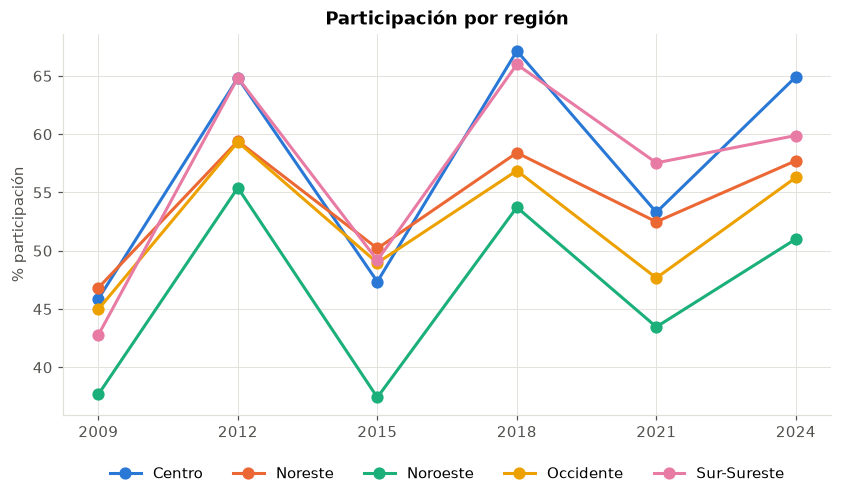

In [10]:
fig, ax = plt.subplots()
for (region, fila), color in zip(part_region.iterrows(), CATEGORICOS):
    ax.plot(fila.index, fila.values, marker="o", color=color, label=region)
ax.set_title("Participación por región")
ax.set_ylabel("% participación")
ax.set_xticks(ANOS)
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

## 11. Cohortes generacionales

Ano de nacimiento aproximado = año de elección - edad. Seguir una misma decada de nacimiento
a través de las elecciones separa el efecto de la edad del efecto generacional.
Se excluyen edades mayores a 100.

In [11]:
nacimiento = df["AELEC"] - df["EDAD"]
decada = (nacimiento // 10 * 10).where(df["EDAD"] <= 100)
part_cohorte = participacion(df.assign(DECADA=decada).dropna(subset=["DECADA"]), ["DECADA", "AELEC"]).unstack()
part_cohorte.index = part_cohorte.index.astype(int).astype(str) + "s"
part_cohorte = part_cohorte.loc["1920s":"2000s"]
part_cohorte

AELEC,2009,2012,2015,2018,2021,2024
DECADA,,,,,,
1920s,36.44,46.15,31.01,31.21,21.90,23.49
1930s,53.96,65.88,52.17,55.93,44.87,46.93
1940s,57.86,73.30,62.67,70.89,63.65,68.37
1950s,54.84,73.19,60.14,72.89,67.55,76.08
1960s,48.63,69.08,54.92,70.11,62.52,71.12
1970s,39.86,61.86,48.81,65.83,56.43,65.60
1980s,34.88,52.70,38.35,58.98,47.58,58.08
1990s,43.98,57.03,37.66,53.21,40.35,49.57
2000s,NaN,NaN,NaN,64.82,46.83,50.40


## 12. Gráfica: mapa de calor cohorte x año

Las celdas vacías corresponden a cohortes que aun no tenían edad para votar.

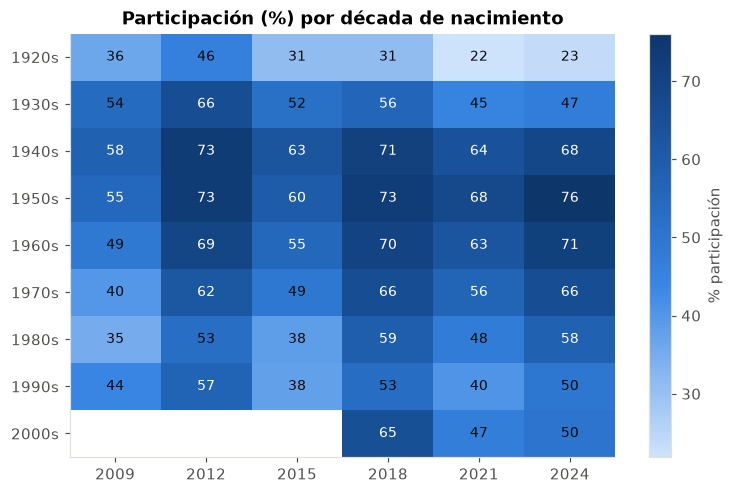

In [12]:
valores = part_cohorte.to_numpy()
media = np.nanmean(valores)
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(valores, cmap=CMAP_AZUL, aspect="auto")
ax.set_xticks(range(len(ANOS)), ANOS)
ax.set_yticks(range(len(part_cohorte.index)), part_cohorte.index)
ax.grid(False)
for i in range(valores.shape[0]):
    for j in range(valores.shape[1]):
        v = valores[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9,
                    color="white" if v > media else "#0b0b0b")
ax.set_title("Participación (%) por década de nacimiento")
fig.colorbar(im, ax=ax, label="% participación")
plt.show()

## 13. Agregación a sección x año

Se suman todos los sexos y edades de cada sección. La sección se identifica por `EDOCVE + SECCION`.

In [13]:
sec_ano = df.groupby(["EDOCVE", "SECCION", "AELEC"])[["LN", "SV", "NV"]].sum().reset_index()
sec_ano["PART"] = sec_ano["SV"] / (sec_ano["SV"] + sec_ano["NV"]) * 100
print(f"Filas sección x año: {len(sec_ano):,}")
print(f"Con SV + NV = 0:     {sec_ano['PART'].isna().sum():,}")

Filas sección x año: 406,866
Con SV + NV = 0:     9,438


## 14. Secciones con historial completo

Solo se conservan las secciones con participación válida en las 6 elecciones. Una sección-año con
SV + NV = 0 significa que todo su padrón quedó como NS (cuadernillos no disponibles), por lo que no
tiene tasa y la sección se descarta.

In [14]:
sec_ano = sec_ano.dropna(subset=["PART"])
n_anos = sec_ano.groupby(["EDOCVE", "SECCION"])["AELEC"].transform("size")
sec_ano = sec_ano[n_anos == len(ANOS)]
print(f"Secciones con 6 elecciones: {sec_ano[['EDOCVE', 'SECCION']].drop_duplicates().shape[0]:,}")
print(f"Personas en LN 2024 cubiertas: {sec_ano.loc[sec_ano['AELEC'] == 2024, 'LN'].sum():,}")

Secciones con 6 elecciones: 54,892
Personas en LN 2024 cubiertas: 80,038,120


## 15. Tabla ancha de participación por sección

Una fila por sección, una columna por elección (`P2009` ... `P2024`).

In [15]:
secciones = sec_ano.pivot(index=["EDOCVE", "SECCION"], columns="AELEC", values="PART")
secciones.columns = COLS_ANOS
secciones.head()

P2009  P2012  P2015  P2018  P2021  P2024
EDOCVE SECCION                                          
1      1        53.30  72.85  54.03  78.20  80.77  79.58
       2        46.08  63.49  39.63  52.90  54.98  58.42
       3        46.59  71.87  44.89  70.01  57.28  71.89
       4        49.84  71.43  40.30  67.70  57.39  71.12
       5        50.40  72.72  44.10  71.07  62.74  65.91

## 16. Función de indicadores de historial

Resume las 6 tasas de cada fila en indicadores comparables:

| Indicador | Que mide |
|---|---|
| `promedio` | Nivel general de participación |
| `desviacion` | Que tan estable es entre elecciones |
| `brecha_pres` | Promedio presidencial - promedio intermedio (dependencia del tipo de elección) |
| `tendencia` | Pendiente en puntos por elección (si sube o baja con el tiempo) |

In [16]:
def indicadores(ancha):
    valores = ancha[COLS_ANOS].to_numpy()
    x = np.arange(len(ANOS)) - (len(ANOS) - 1) / 2
    return pd.DataFrame({
        "promedio": valores.mean(axis=1),
        "desviacion": valores.std(axis=1, ddof=1),
        "brecha_pres": ancha[PRESIDENCIALES].mean(axis=1).to_numpy() - ancha[INTERMEDIAS].mean(axis=1).to_numpy(),
        "tendencia": (valores - valores.mean(axis=1, keepdims=True)) @ x / (x ** 2).sum(),
    }, index=ancha.index)

## 17. Indicadores por sección

In [17]:
secciones = secciones.join(indicadores(secciones))
secciones[["promedio", "desviacion", "brecha_pres", "tendencia"]].describe()

,promedio,desviacion,brecha_pres,tendencia
count,"54,892.00","54,892.00","54,892.00","54,892.00"
mean,56.25,9.81,13.07,2.03
std,9.18,3.74,7.03,2.17
min,10.45,0.66,-18.64,-9.23
25%,50.39,7.16,7.80,0.54
50%,56.14,9.71,13.34,2.13
75%,62.10,12.40,18.12,3.47
max,96.12,34.81,45.60,15.37


## 18. Atributos de la sección

Tipo de sección y lista nominal de 2024 (el corte más reciente) y región.

In [18]:
attr_2024 = (
    df[df["AELEC"] == 2024]
    .groupby(["EDOCVE", "SECCION"], observed=True)
    .agg(TIPOSEC=("TIPOSEC", "first"), LN2024=("LN", "sum"))
)
secciones = secciones.join(attr_2024)
secciones["REGION"] = secciones.index.get_level_values("EDOCVE").map(REGION_POR_EDO)
print(secciones[["TIPOSEC", "REGION"]].isna().sum().to_string())
secciones.head()

TIPOSEC    0
REGION     0


P2009  P2012  P2015  P2018  P2021  P2024  promedio  \
EDOCVE SECCION                                                       
1      1        53.30  72.85  54.03  78.20  80.77  79.58     69.79   
       2        46.08  63.49  39.63  52.90  54.98  58.42     52.58   
       3        46.59  71.87  44.89  70.01  57.28  71.89     60.42   
       4        49.84  71.43  40.30  67.70  57.39  71.12     59.63   
       5        50.40  72.72  44.10  71.07  62.74  65.91     61.16   

                desviacion  brecha_pres  tendencia TIPOSEC  LN2024     REGION  
EDOCVE SECCION                                                                 
1      1             12.78        14.18       5.12       U    2336  Occidente  
       2              8.59        11.37       1.41       U     926  Occidente  
       3             12.62        21.67       3.08       U    1750  Occidente  
       4             12.74        20.91       2.62       U    1399  Occidente  
       5             11.52        17.48       2.13       U     748  Occidente

## 19. Gráfica: distribución de la participación promedio por sección

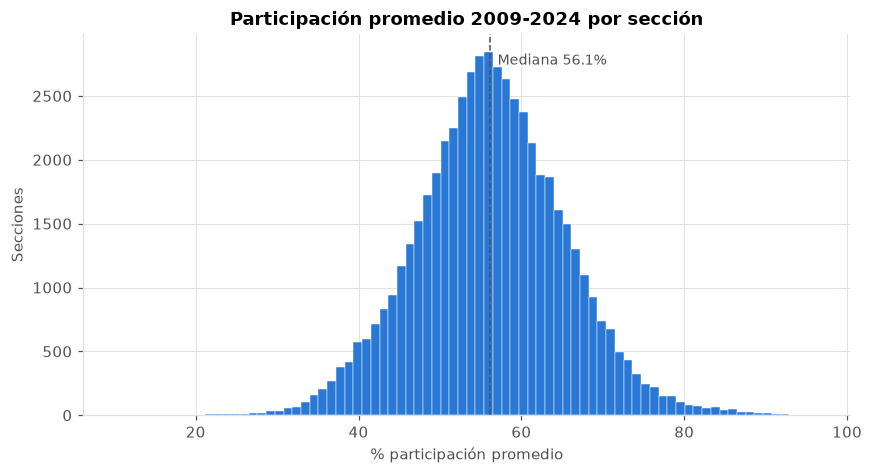

In [19]:
fig, ax = plt.subplots()
ax.hist(secciones["promedio"], bins=80, color=AZUL, edgecolor="white", linewidth=0.3)
ax.axvline(secciones["promedio"].median(), color=TEXTO, linewidth=1, linestyle="--")
ax.annotate(f"Mediana {secciones['promedio'].median():.1f}%", (secciones["promedio"].median(), ax.get_ylim()[1] * 0.92),
            xytext=(5, 0), textcoords="offset points", color=TEXTO, fontsize=9)
ax.set_title("Participación promedio 2009-2024 por sección")
ax.set_xlabel("% participación promedio")
ax.set_ylabel("Secciones")
plt.show()

## 20. Gráfica: nivel vs dependencia de la elección presidencial

Cada punto es una sección. Eje x: participación promedio. Eje y: brecha presidencial - intermedia.

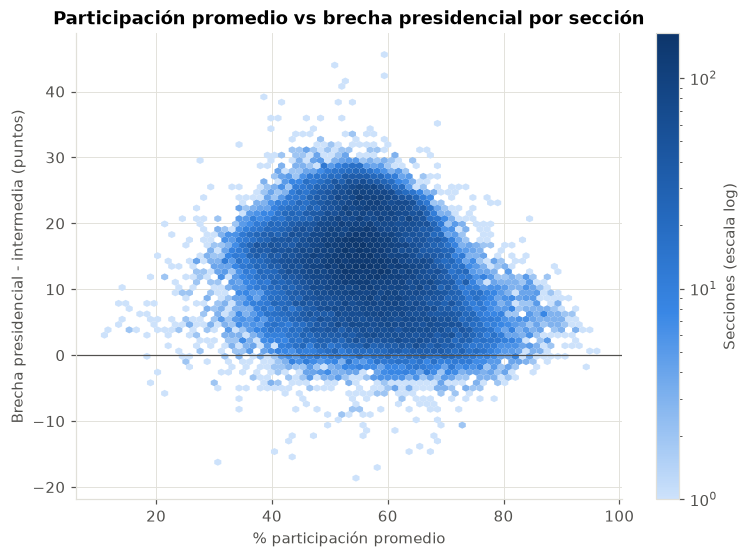

In [20]:
fig, ax = plt.subplots(figsize=(8, 5.5))
hb = ax.hexbin(secciones["promedio"], secciones["brecha_pres"], gridsize=70, cmap=CMAP_AZUL,
               mincnt=1, bins="log", linewidths=0)
ax.axhline(0, color=TEXTO, linewidth=0.8)
ax.set_title("Participación promedio vs brecha presidencial por sección")
ax.set_xlabel("% participación promedio")
ax.set_ylabel("Brecha presidencial - intermedia (puntos)")
fig.colorbar(hb, ax=ax, label="Secciones (escala log)")
plt.show()

## 21. Persistencia: correlación entre elecciones

Si una sección participa mucho en una elección, tiende a participar mucho en las demás?

In [21]:
corr_anos = secciones[COLS_ANOS].corr()
corr_anos

,P2009,P2012,P2015,P2018,P2021,P2024
P2009,1.00,0.67,0.66,0.46,0.50,0.44
P2012,0.67,1.00,0.60,0.78,0.67,0.72
P2015,0.66,0.60,1.00,0.54,0.60,0.45
P2018,0.46,0.78,0.54,1.00,0.78,0.82
P2021,0.50,0.67,0.60,0.78,1.00,0.73
P2024,0.44,0.72,0.45,0.82,0.73,1.00


## 22. Correlación entre indicadores

In [22]:
secciones[["promedio", "desviacion", "brecha_pres", "tendencia", "LN2024"]].corr()

,promedio,desviacion,brecha_pres,tendencia,LN2024
promedio,1.00,-0.11,-0.22,0.06,-0.14
desviacion,-0.11,1.00,0.75,0.72,0.00
brecha_pres,-0.22,0.75,1.00,0.58,0.09
tendencia,0.06,0.72,0.58,1.00,-0.09
LN2024,-0.14,0.00,0.09,-0.09,1.00


## 23. Indicadores por tipo de sección

In [23]:
secciones.groupby("TIPOSEC", observed=True)[["promedio", "desviacion", "brecha_pres", "tendencia"]].mean()

,promedio,desviacion,brecha_pres,tendencia
TIPOSEC,,,,
M,56.97,9.71,10.91,1.87
R,58.93,9.10,8.52,1.49
U,55.02,10.12,15.29,2.28


## 24. Indicadores por región

In [24]:
secciones.groupby("REGION")[["promedio", "desviacion", "brecha_pres", "tendencia"]].mean().sort_values("promedio")

,promedio,desviacion,brecha_pres,tendencia
REGION,,,,
Noroeste,49.16,9.66,13.46,1.65
Occidente,54.09,8.15,9.49,1.24
Noreste,56.89,7.37,8.98,1.85
Sur-Sureste,58.48,10.99,12.52,2.32
Centro,58.86,10.65,16.43,2.51


## 25. Relación con PJ 2025

Participación por sección en la elección judicial, unida por `EDOCVE + SECCION`.
PJ 2025 usa marco DERFE 2025, por lo que algunas secciones no empatan.

In [25]:
pj = pd.read_parquet(PQ_PJ2025, columns=["EDOCVE", "SECCION", "SV", "NV"])
pj = pj.groupby(["EDOCVE", "SECCION"])[["SV", "NV"]].sum()
pj_part = (pj["SV"] / (pj["SV"] + pj["NV"]) * 100).rename("P_PJ2025")
pj_part.index = pj_part.index.set_levels([pj_part.index.levels[0].astype("int8"),
                                          pj_part.index.levels[1].astype("int32")])

secciones = secciones.join(pj_part)
print(f"Secciones con dato PJ 2025: {secciones['P_PJ2025'].notna().sum():,} de {len(secciones):,}")
print(f"Correlación promedio federal vs PJ 2025: {secciones['promedio'].corr(secciones['P_PJ2025']):.3f}")
print(f"Correlación 2024 vs PJ 2025:             {secciones['P2024'].corr(secciones['P_PJ2025']):.3f}")
del pj, pj_part

Secciones con dato PJ 2025: 53,825 de 54,892
Correlación promedio federal vs PJ 2025: 0.276
Correlación 2024 vs PJ 2025:             0.272


## 26. Gráfica: participación federal promedio vs PJ 2025

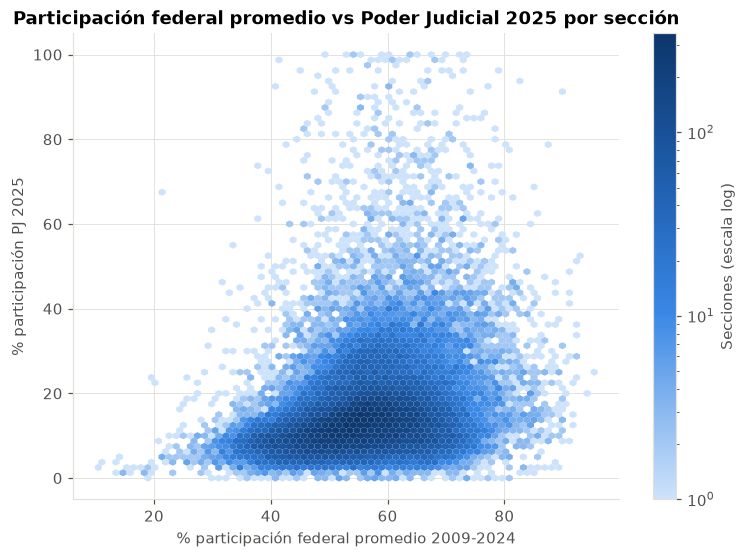

In [26]:
con_pj = secciones.dropna(subset=["P_PJ2025"])
fig, ax = plt.subplots(figsize=(8, 5.5))
hb = ax.hexbin(con_pj["promedio"], con_pj["P_PJ2025"], gridsize=70, cmap=CMAP_AZUL,
               mincnt=1, bins="log", linewidths=0)
ax.set_title("Participación federal promedio vs Poder Judicial 2025 por sección")
ax.set_xlabel("% participación federal promedio 2009-2024")
ax.set_ylabel("% participación PJ 2025")
fig.colorbar(hb, ax=ax, label="Secciones (escala log)")
plt.show()
del con_pj

## 27. Agregación a celda demografica x año

Celda = sección x sexo x grupo de edad. Es la unidad más fina con historial: combina el lugar
(sección) con el perfil sociodemográfico (sexo y edad).
Nota: la celda no sigue a las mismas personas; cada año el grupo de edad se renueva.

In [27]:
claves = ["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD"]
cel_ano = df.groupby(claves + ["AELEC"], observed=True)[["SV", "NV"]].sum()
cel_ano["VOTANTES"] = cel_ano["SV"] + cel_ano["NV"]
cel_ano["PART"] = cel_ano["SV"] / cel_ano["VOTANTES"] * 100
print(f"Filas celda x año: {len(cel_ano):,}")

Filas celda x año: 6,488,866


## 28. Celdas con historial completo y tamaño mínimo

Se conservan celdas con las 6 elecciones y al menos `MIN_VOTANTES` personas (SV + NV) en cada una.

In [28]:
celdas = cel_ano["PART"].unstack("AELEC")
min_votantes = cel_ano["VOTANTES"].unstack("AELEC").min(axis=1)
celdas.columns = COLS_ANOS

completas = celdas.notna().all(axis=1)
grandes = min_votantes >= MIN_VOTANTES
print(f"Celdas totales:                {len(celdas):,}")
print(f"Con 6 elecciones:              {completas.sum():,}")
print(f"Con 6 elecciones y tamaño min: {(completas & grandes).sum():,}")

celdas = celdas[completas & grandes]
del cel_ano, min_votantes

Celdas totales:                1,161,617
Con 6 elecciones:              873,808
Con 6 elecciones y tamaño min: 657,497


## 29. Indicadores por celda

In [29]:
celdas = celdas.join(indicadores(celdas)).reset_index()
celdas = celdas.merge(attr_2024[["TIPOSEC"]], left_on=["EDOCVE", "SECCION"], right_index=True, how="left")
celdas["REGION"] = celdas["EDOCVE"].map(REGION_POR_EDO)
celdas[["promedio", "desviacion", "brecha_pres", "tendencia"]].describe()

,promedio,desviacion,brecha_pres,tendencia
count,"657,497.00","657,497.00","657,497.00","657,497.00"
mean,56.92,11.21,13.05,1.84
std,13.79,4.10,8.30,2.79
min,4.04,0.58,-35.49,-14.60
25%,46.97,8.26,7.21,0.00
50%,57.46,10.92,13.03,1.84
75%,67.35,13.84,18.70,3.64
max,99.46,39.41,51.64,19.88


## 30. Fuentes de variación de la participación

Eta cuadrada: proporción de la varianza del promedio de participación por celda que explica cada factor
por si solo. Indica que variables separan mejor a los grupos y deben pesar en la segmentación.

In [30]:
def eta2(valores, grupos):
    media_grupo = valores.groupby(grupos, observed=True).transform("mean")
    return ((media_grupo - valores.mean()) ** 2).sum() / ((valores - valores.mean()) ** 2).sum()

factores = {
    "Grupo de edad": celdas["GRUPO_EDAD"],
    "Sexo": celdas["SEXO"],
    "Tipo de seccion": celdas["TIPOSEC"],
    "Region": celdas["REGION"],
    "Entidad": celdas["EDOCVE"],
    "Seccion": celdas["EDOCVE"].astype(int) * 100_000 + celdas["SECCION"],
}
fuentes = pd.Series({f: eta2(celdas["promedio"], g) for f, g in factores.items()}, name="eta2")
fuentes.sort_values(ascending=False).to_frame()

,eta2
Seccion,0.41
Grupo de edad,0.39
Entidad,0.12
Region,0.07
Sexo,0.06
Tipo de seccion,0.01


## 31. Gráfica: fuentes de variación

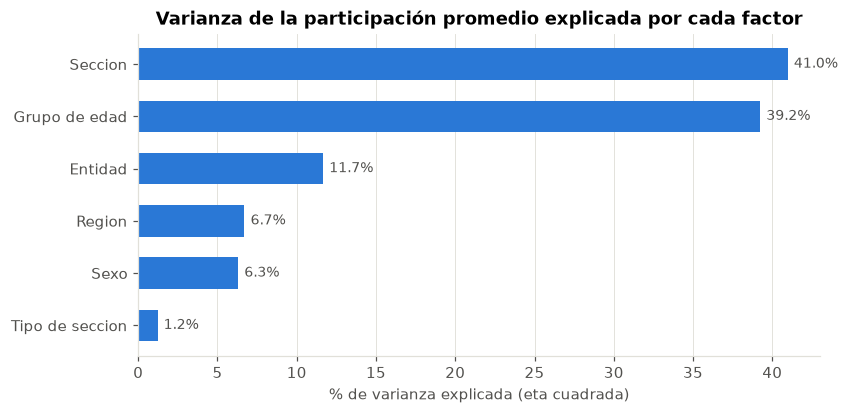

In [31]:
orden = fuentes.sort_values()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(orden.index, orden.values * 100, color=AZUL, height=0.6)
for y, v in enumerate(orden.values * 100):
    ax.annotate(f"{v:.1f}%", (v, y), xytext=(4, 0), textcoords="offset points", va="center",
                color=TEXTO, fontsize=9)
ax.set_title("Varianza de la participación promedio explicada por cada factor")
ax.set_xlabel("% de varianza explicada (eta cuadrada)")
ax.grid(axis="y", visible=False)
plt.show()

## 32. Brecha presidencial y tendencia por grupo de edad y sexo

Que perfiles dependen más de la elección presidencial y cuales estan cambiando con el tiempo.

In [32]:
celdas.pivot_table(index="GRUPO_EDAD", columns="SEXO", values=["promedio", "brecha_pres", "tendencia"],
                   aggfunc="mean", observed=True).rename(columns={0: "H", 1: "M"})

brecha_pres       promedio       tendencia     
SEXO                 H     M        H     M         H    M
GRUPO_EDAD                                                
18-24            13.69 14.35    44.52 53.06      1.51 1.83
25-29            13.86 15.41    39.41 50.69      1.38 1.75
30-39            13.45 14.83    45.45 57.46      1.57 2.07
40-49            12.54 13.63    54.64 64.68      1.29 1.77
50-59            11.71 12.53    61.70 68.10      1.32 1.76
60-69            11.06 11.79    68.15 69.19      1.97 2.43
70-79            10.24 11.91    68.45 64.58      2.51 3.03
80+              10.24 12.65    50.80 43.01      2.37 3.31

## 33. Guardado de tablas

Tablas listas para la segmentacion en `DATA/PREPROCESSED/`.

In [33]:
secciones.reset_index().to_parquet(PQ_SECCIONES, index=False)
celdas.to_parquet(PQ_CELDAS, index=False)

for f in [PQ_SECCIONES, PQ_CELDAS]:
    print(f"Guardado: {f.name} ({pd.read_parquet(f, columns=['EDOCVE']).shape[0]:,} filas, "
          f"{f.stat().st_size / 1024**2:.1f} MB)")

Guardado: secciones_historial.parquet (54,892 filas, 5.5 MB)
Guardado: celdas_historial.parquet (657,497 filas, 29.6 MB)


## 34. Liberación de memoria

In [34]:
del df, sec_ano, secciones, celdas
gc.collect()
print("Memoria liberada.")

Memoria liberada.


## Resumen de hallazgos

**Tablas generadas (`DATA/PREPROCESSED/`)**

| Archivo | Unidad | Filas | Contenido |
|---|---|---|---|
| `secciones_historial.parquet` | Sección | 54,892 | P2009-P2024, indicadores, TIPOSEC, LN2024, REGION, P_PJ2025 |
| `celdas_historial.parquet` | Sección x sexo x grupo de edad | 657,497 | P2009-P2024, indicadores, TIPOSEC, REGION |

- 54,892 secciones tienen tasa válida en las 6 elecciones (cubren 80 de 98 millones de LN 2024). 9,438 seccion-año tienen todo su padrón como NS.
- Las celdas exigen al menos 20 votantes potenciales (SV + NV) en cada elección.

**Región**

- Noroeste es la región con menor participación en todas las elecciones (51% en 2024, 7 a 14 puntos debajo de las demás).
- Centro y Sur-Sureste son las más altas y las que más dependen de la elección presidencial.

**Generaciones**

- Hay efecto de primera elección: quienes votan por primera vez participan más que el grupo de edad inmediato siguiente (cohorte 2000s: 65% en 2018, 47% en 2021).
- Las cohortes 1940s-1960s son las más participativas en todas las elecciones; la caída a partir de 1920s-1930s es por edad avanzada.
- La cohorte 1980s sube de 35% (2009) a 58% (2024): la participación aumenta conforme la generación envejece.

**Historial por sección**

- Participación promedio con distribución casi normal (mediana 56%, 50% de las secciones entre 50 y 62%).
- Alta persistencia: la correlación entre elecciones del mismo tipo es 0.66-0.82. Las secciones mantienen su nivel relativo.
- La brecha presidencial es positiva en casi todas las secciones (mediana +13 puntos); es mayor en lo urbano (15) que en lo rural (8.5).
- La tendencia es positiva (mediana +2 puntos por elección).
- `desviacion`, `brecha_pres` y `tendencia` estan correlacionadas entre si (0.58-0.75) y casi nada con `promedio`. Para clustering conviene usar `promedio` + `brecha_pres` + `tendencia` y no las tres medidas de variabilidad juntas.

**PJ 2025**

- Correlación debil con la participación federal (0.28): la elección judicial moviliza de manera distinta. Es una dimension adicional, no redundante.

**Fuentes de variación (eta cuadrada sobre celdas)**

- Sección (41%) y grupo de edad (39%) explican casi toda la variación; sexo explica 6% y tipo de sección solo 1%.
- Las mujeres participan más en todas las edades hasta 60-69; desde 70-79 la relacion se invierte y los hombres participan más.

**Implicaciones para la segmentación**

- Los perfiles deben combinar edad (quien) con el historial de la sección (donde), ya que juntos explican la mayor parte de la variación.
- Variables candidatas: grupo de edad, sexo, promedio, brecha_pres, tendencia, región y P_PJ2025.